<hr>

# **<span style="color: #87CEEB;"> CS437 / CS5317 / EE414 / EE513 Deep Learning Programming Assignment 3 Part-1D</span>**

<hr>

# <span style="color: #9370DB;">**Submission Guidelines**</span>

- <span style="color: #9370DB;">Please rename the file to `<RollNumber>_PA3_1D`.</span>
- <span style="color: #9370DB;">Please also submit a **.py** file of every Notebook. You can do this by exporting your **ipynb** to a Python script.</span>
- <span style="color: #9370DB;">Please submit a zipped folder of both your Jupyter Notebooks and Python script files.</span>

<hr>


### Name: Sameer Rahil
### Roll Number: 27100162


## Task Overview

In this notebook you will compare two GAN architectures:

**1. DCGAN (Deep Convolutional GAN)**  
**2. WGAN‑GP (Wasserstein GAN with Gradient Penalty)**

Goal:

- Train GANs on **Fashion‑MNIST** and **CIFAR‑10**
- Observe **mode collapse**
- Compare **training stability**
- Analyze **results**



## Assignment Tasks

### Stage 1 : Dataset Setup
Fashion‑MNIST and CIFAR‑10 datasets are loaded automatically. You may use a subset or apply preprocessing to the datasets to shorten training times.

### Stage 2 : Implement DCGAN
Students implement:

- Generator
- Discriminator
- Training loop

### Stage 3 : Implement WGAN‑GP

Students implement:

- Critic
- Gradient Penalty
- WGAN training loop

### Stage 4 : Visualization

Students should visualize:

- Generated image grids
- All possible training loss curves

### Stage 5 : Analysis

Discuss:

- Mode collapse behaviour
- Training stability
- Differences between DCGAN and WGAN‑GP


# <span style="color:#9370DB;">Mode Collapse (What problem are we solving?)</span>

A common failure mode in GAN training is **mode collapse**: the generator learns to produce only a **small set of outputs** (or even one output) that consistently fools the discriminator/critic.

### What it looks like
- Many generated samples in a grid look **nearly identical**
- Diversity is low (same shapes, colors, poses repeating)
- Training may look “stable” for a while, but the generator stops improving

### Why it happens (intuition)
The generator is rewarded for producing samples that fool the discriminator. If it finds an “easy trick” (one mode) that works, it may keep repeating it rather than covering the full data distribution.

### Learning outcome in this notebook
You will **train DCGAN and WGAN-GP**, then **diagnose mode collapse** using:
- **Side-by-side sample grids**
- **Loss curves**

Finally, you will argue **how WGAN-GP and DCGAN handle mode collapse**


# <span style="color:#9370DB;">Learning Outcomes</span>

By the end of this notebook you should be able to:

- Implement **DCGAN** and **WGAN-GP** training pipelines
- Explain **why mode collapse occurs** and how it appears in results
- Use **visualizations + metrics** to compare GAN behavior
- Demonstrate a practical mitigation strategy (**WGAN-GP**) for improving diversity and stability


In [1]:

# Imports

import os
import random
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as T
from torchvision.utils import make_grid, save_image

import matplotlib.pyplot as plt
from tqdm.auto import tqdm


# <span style="color:#9370DB;"> Visualizations</span>

To make the comparison clearer (and grading easier), we include utilities for:

- **Side-by-side grid comparison**: DCGAN vs WGAN-GP using the *same* latent noise

In [2]:
# ===============================
# Extra Visualizations
# ===============================

@torch.no_grad()
def generate_grid(G, fixed_noise, nrow=8):
    G.eval()
    fake = G(fixed_noise).detach().cpu()
    fake = (fake * 0.5 + 0.5).clamp(0, 1)  # [-1,1] -> [0,1]
    grid = make_grid(fake, nrow=nrow, normalize=False)
    G.train()
    return grid

@torch.no_grad()
def compare_side_by_side(G1, G2, fixed_noise, title_left="Model 1", title_right="Model 2", nrow=8):
    """Side-by-side visualization using the SAME fixed noise."""
    grid1 = generate_grid(G1, fixed_noise, nrow=nrow)
    grid2 = generate_grid(G2, fixed_noise, nrow=nrow)

    plt.figure(figsize=(12,6))
    plt.subplot(1,2,1)
    plt.imshow(grid1.permute(1,2,0))
    plt.axis("off")
    plt.title(title_left)

    plt.subplot(1,2,2)
    plt.imshow(grid2.permute(1,2,0))
    plt.axis("off")
    plt.title(title_right)
    plt.show()


In [3]:

# Configuration

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Z_DIM = 100
IMG_SIZE = 64
BATCH_SIZE = 128

OUT_DIR = "pa3_1d_outputs"
os.makedirs(OUT_DIR, exist_ok=True)


Device: cuda


## Dataset Loading (Fashion‑MNIST and CIFAR‑10)

#### You can use a subset of the datasets to shorten training times

In [4]:

def get_loader(dataset_name):

    if dataset_name == "fashion":

        transform = T.Compose([
            T.Resize(64),
            T.ToTensor(),
            T.Normalize((0.5,), (0.5,))
        ])

        dataset = torchvision.datasets.FashionMNIST(
            root="./data",
            train=True,
            download=True,
            transform=transform
        )

        channels = 1

    elif dataset_name == "cifar":

        transform = T.Compose([
            T.Resize(64),
            T.ToTensor(),
            T.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
        ])

        dataset = torchvision.datasets.CIFAR10(
            root="./data",
            train=True,
            download=True,
            transform=transform
        )

        channels = 3

    loader = DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=True)

    return loader, channels


fashion_loader, FASHION_C = get_loader("fashion")
cifar_loader, CIFAR_C = get_loader("cifar")

print("Fashion batches:",len(fashion_loader))
print("CIFAR batches:",len(cifar_loader))


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 176kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.7MB/s]
100%|██████████| 170M/170M [00:13<00:00, 12.9MB/s]


Fashion batches: 469
CIFAR batches: 391


## Preview Dataset

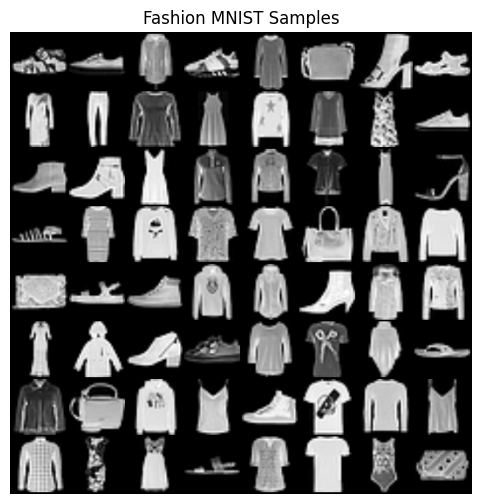

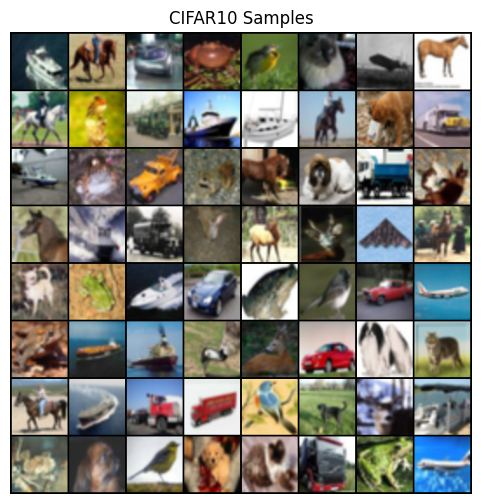

In [5]:

def show_samples(loader,title):

    imgs,_ = next(iter(loader))
    imgs = imgs[:64]

    imgs = (imgs*0.5+0.5).clamp(0,1)

    grid = make_grid(imgs,nrow=8)

    plt.figure(figsize=(6,6))
    plt.imshow(grid.permute(1,2,0))
    plt.axis("off")
    plt.title(title)
    plt.show()


show_samples(fashion_loader,"Fashion MNIST Samples")
show_samples(cifar_loader,"CIFAR10 Samples")


# <span style="color:#9370DB;">Section A — DCGAN Implementation</span>

In this section you will implement a **Deep Convolutional Generative Adversarial Network (DCGAN)** and train it on the provided dataset.

DCGAN improves the stability of traditional GANs by replacing fully connected layers with **deep convolutional architectures**.

Students must implement the following components:

### 1. Generator
The **Generator** takes a random noise vector \(z\) sampled from a latent distribution and transforms it into a synthetic image.

You should implement:
- Latent noise input \(z\)
- Series of **ConvTranspose2D (deconvolution) layers**
- **Batch Normalization if required**
- **activation layers**
- Final **Tanh output layer** to produce images in the range \([-1,1]\)

---

### 2. Discriminator
The **Discriminator** acts as a binary classifier that distinguishes between **real images** from the dataset and **fake images** generated by the generator.

You should implement:
- **Convolutional layers** for feature extraction
- **activations**
- **Batch Normalization if required**
- Final **Sigmoid output layer** that outputs the probability of the image being real.

---

### 3. Training Loop
You will implement the GAN training process where:

1. The **Discriminator** learns to distinguish real images from fake images.
2. The **Generator** learns to generate images that fool the discriminator.

Each iteration should include:

- Sampling **real images** from the dataset
- Generating **fake images** using random noise
- Updating the **Discriminator loss**
- Updating the **Generator loss**
- Logging the losses for visualization

---

After training, visualize:

- Generated image samples
- Training loss curves
- Signs of **mode collapse** in the generated outputs.

In [6]:
class DCGAN_Generator(nn.Module):

    def __init__(self,z_dim=100,img_channels=1):
        super().__init__()

        # TODO: Implement Generator
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim,512,4,1,0,bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512,256,4,2,1,bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256,128,4,2,1,bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128,64,4,2,1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64,img_channels,4,2,1,bias=False),
            nn.Tanh()
        )

    def forward(self,x):
        return self.net(x)

In [7]:
class DCGAN_Discriminator(nn.Module):

    def __init__(self,img_channels=1):
        super().__init__()

        # TODO: Implement Discriminator
        self.net = nn.Sequential(
            nn.Conv2d(img_channels,64,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(64,128,4,2,1,bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(128,256,4,2,1,bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(256,512,4,2,1,bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2,True),
            # nn.BatchNorm2d(256),
            # nn.LeakyReLU(0.2,True),
            # nn.Conv2d(256,512,4,2,1,bias=False),
            # nn.BatchNorm2d(512),
            nn.Conv2d(512,1,4,1,0,bias=False),
            nn.Sigmoid()
        )

    def forward(self,x):
        return self.net(x).view(-1)

In [8]:
def train_dcgan(loader,channels):

    # TODO: implement training loop
    G = DCGAN_Generator(Z_DIM,channels).to(device)
    D = DCGAN_Discriminator(channels).to(device)

    def init_weights(m):
        if isinstance(m,(nn.Conv2d,nn.ConvTranspose2d,nn.BatchNorm2d)):
            nn.init.normal_(m.weight.data,0.0,0.02)
            if getattr(m,"bias",None) is not None:
                nn.init.constant_(m.bias.data,0)

    G.apply(init_weights)
    D.apply(init_weights)

    criterion = nn.BCELoss()
    opt_G = optim.Adam(G.parameters(),lr=2e-4,betas=(0.5,0.999))
    opt_D = optim.Adam(D.parameters(),lr=2e-4,betas=(0.5,0.999))

    epochs = 5
    losses = {"D_loss":[],"G_loss":[]}

    for epoch in range(epochs):
        for real,_ in tqdm(loader,leave=False):
            real = real.to(device)
            bsz = real.size(0)

            noise = torch.randn(bsz,Z_DIM,1,1,device=device)
            fake =G(noise)
            D_real = D(real)
            D_fake= D(fake.detach())
            real_labels =torch.ones_like(D_real)
            fake_labels =torch.zeros_like(D_fake)
            loss_real = criterion(D_real,real_labels)
            loss_fake = criterion(D_fake,fake_labels)
            d_loss =0.5*(loss_real +loss_fake)
            opt_D.zero_grad()
            d_loss.backward()
            opt_D.step()
            output = D(fake)
            g_loss = criterion(output,torch.ones_like(output))
            opt_G.zero_grad()
            g_loss.backward()
            opt_G.step()
            losses["D_loss"].append(d_loss.item())
            losses["G_loss"].append(g_loss.item())

    return G,D,losses

# <span style="color:#9370DB;">Section B — WGAN-GP Implementation</span>

In this section you will implement a **Wasserstein Generative Adversarial Network with Gradient Penalty (WGAN-GP)**.

Traditional GANs (including DCGAN) often suffer from **training instability and mode collapse**.  
WGAN addresses this issue by replacing the standard GAN loss with the **Wasserstein distance**, which provides a smoother and more stable training signal.

Instead of a discriminator, WGAN uses a **critic**, which estimates how real or fake a sample is without using a probability output.

Students must implement the following components:

---

### 1. Critic

The **Critic** replaces the discriminator in WGAN.

Unlike a discriminator, the critic:

- Outputs a **real-valued score** instead of a probability
- Does **not use a sigmoid activation**
- Is trained to assign **higher scores to real images** and **lower scores to generated images**

You should implement:

- Convolutional layers for feature extraction
- **Activations**
- No final sigmoid layer
- Output representing the **critic score**

---

### 2. Gradient Penalty

WGAN-GP enforces a **Lipschitz constraint** using a **gradient penalty** instead of weight clipping.

The gradient penalty ensures that the gradient norm of the critic with respect to the input remains close to **1**.

The penalty term is defined as:

The penalty term is defined as:

$$
\mathcal{L}_{GP}
=
\lambda \,
\mathbb{E}_{\hat{x}}
\left[
\left(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1\right)^2
\right]
$$

where \( \hat{x} \) is sampled along the line between real and generated images.

Students must implement:

- Interpolation between **real and fake samples**
- Gradient computation using **autograd**
- The **gradient penalty loss term**

---

### 3. Training Loop

The WGAN training process differs from DCGAN.

Key differences include:

- The **critic is trained multiple times per generator update** (commonly \(n_{critic}=5\))
- The critic minimizes the **Wasserstein loss**
- The generator maximizes the critic's score on generated images
- The **gradient penalty** is added to the critic loss

During training you should:

- Update the **critic multiple times**
- Compute the **gradient penalty**
- Update the **generator**
- Record losses for visualization and comparison with DCGAN

---

After training, compare results with DCGAN by visualizing:

- Generated image samples
- Training loss curves
- Signs of **mode collapse** and differences in sample diversity

In [9]:
class WGAN_Critic(nn.Module):

    def __init__(self,img_channels):
        super().__init__()

        # TODO: implement critic
        self.net = nn.Sequential(
            nn.Conv2d(img_channels,64,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(64,128,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(128,256,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(256,512,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(512,1,4,1,0,bias=False)
        )

    def forward(self,x):
        return self.net(x).view(-1)

In [10]:
def gradient_penalty(critic,real,fake):

    # TODO: implement gradient penalty
    bsz = real.size(0)
    alpha = torch.rand(bsz,1,1,1,device=real.device)
    interpolated = alpha * real + (1 - alpha) * fake
    interpolated.requires_grad_(True)

    mixed_scores = critic(interpolated)

    gradients = torch.autograd.grad(
        inputs=interpolated,
        outputs=mixed_scores,
        grad_outputs=torch.ones_like(mixed_scores),
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients = gradients.view(bsz,-1)
    gp = ((gradients.norm(2,dim=1) - 1) ** 2).mean()
    return gp

In [11]:
def train_wgan(loader,channels):

    # TODO: implement WGAN training
    G = DCGAN_Generator(Z_DIM,channels).to(device)
    C = WGAN_Critic(channels).to(device)

    def init_weights(m):
        if isinstance(m,(nn.Conv2d,nn.ConvTranspose2d,nn.BatchNorm2d)):
            nn.init.normal_(m.weight.data,0.0,0.02)
            if getattr(m,"bias",None) is not None:
                nn.init.constant_(m.bias.data,0)

    G.apply(init_weights)
    C.apply(init_weights)

    opt_G = optim.Adam(G.parameters(),lr=1e-4,betas=(0.0,0.9))
    opt_C = optim.Adam(C.parameters(),lr=1e-4,betas=(0.0,0.9))

    epochs = 5
    lambda_gp = 10
    n_critic = 5
    losses = {"C_loss":[],"G_loss":[],"GP":[]}

    for epoch in range(epochs):
        for real,_ in tqdm(loader,leave=False):
            real = real.to(device)
            bsz =real.size(0)

            for _ in range(n_critic):
                noise =torch.randn(bsz,Z_DIM,1,1,device=device)
                fake = G(noise)
                critic_real = C(real).mean()
                critic_fake = C(fake.detach()).mean()
                gp = gradient_penalty(C,real,fake.detach())
                c_loss = -(critic_real -critic_fake) + lambda_gp * gp
                opt_C.zero_grad()
                c_loss.backward()
                opt_C.step()
            noise = torch.randn(bsz,Z_DIM,1,1,device=device)
            fake = G(noise)
            g_loss = -C(fake).mean()
            opt_G.zero_grad()
            g_loss.backward()
            opt_G.step()
            losses["C_loss"].append(c_loss.item())
            losses["G_loss"].append(g_loss.item())
            losses["GP"].append(gp.item())

    return G,C,losses

In [12]:
dcgan_fashion_G,dcgan_fashion_D,dcgan_fashion_losses = train_dcgan(fashion_loader,FASHION_C)

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

In [13]:
wgan_fashion_G,wgan_fashion_C,wgan_fashion_losses = train_wgan(fashion_loader,FASHION_C)

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/469 [00:00<?, ?it/s]


# Visualization

Students should visualize:

- Generator samples
- Loss curves


In [14]:

def plot_losses(loss_dict):

    for k,v in loss_dict.items():
        plt.plot(v,label=k)

    plt.legend()
    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.show()


In [1]:
print("DCGAN Fashion Loss Curve and then WGAN Fashion Loss Curve:")

DCGAN Fashion Loss Curve and then WGAN Fashion Loss Curve:


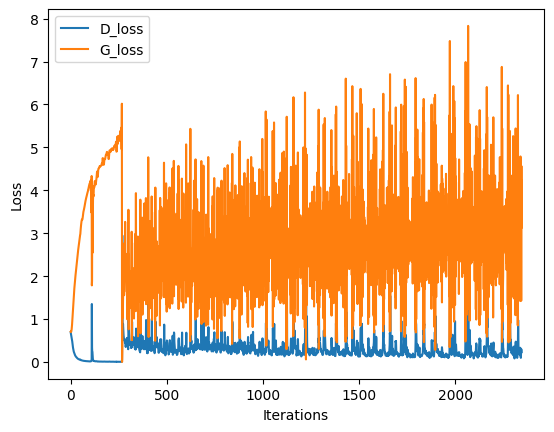

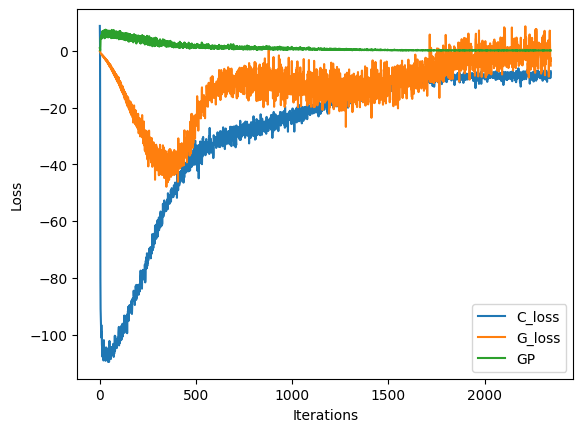

In [ ]:
# print("DCGAN Fashion Loss Curve:")
plot_losses(dcgan_fashion_losses)
# print("WGAN Fashion Loss Curve:")
plot_losses(wgan_fashion_losses)


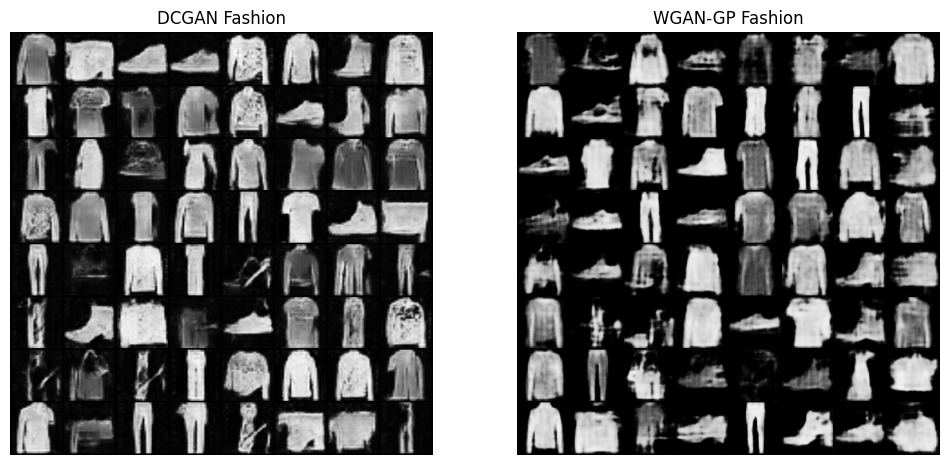

In [16]:
fixed_noise = torch.randn(64,Z_DIM,1,1,device=device)
compare_side_by_side(dcgan_fashion_G,wgan_fashion_G,fixed_noise,title_left="DCGAN Fashion",title_right="WGAN-GP Fashion",nrow=8)

In [17]:
# fixed_noise_cifar = torch.randn(64,Z_DIM,1,1,device=device)
# compare_side_by_side(dcgan_cifar_G,wgan_cifar_G,fixed_noise_cifar,title_left="DCGAN CIFAR10",title_right="WGAN-GP CIFAR10",nrow=8)

NameError: name 'dcgan_cifar_G' is not defined

In [ ]:
# dcgan_cifar_G,dcgan_cifar_D,dcgan_cifar_losses = train_dcgan(cifar_loader,CIFAR_C)
# wgan_cifar_G,wgan_cifar_C,wgan_cifar_losses = train_wgan(cifar_loader,CIFAR_C)
# # plot_losses(dcgan_cifar_losses)
# plot_losses(wgan_cifar_losses)
# fixed_noise_cifar = torch.randn(64,Z_DIM,1,1,device=device)
# compare_side_by_side(dcgan_cifar_G,wgan_cifar_G,fixed_noise_cifar,title_left="DCGAN CIFAR10",title_right="WGAN-GP CIFAR10",nrow=8)

In [18]:
dcgan_cifar_G,dcgan_cifar_D,dcgan_cifar_losses = train_dcgan(cifar_loader,CIFAR_C)
wgan_cifar_G,wgan_cifar_C,wgan_cifar_losses = train_wgan(cifar_loader,CIFAR_C)

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

In [2]:
print("DCGAN CIFAR Loss Curve and then WGAN CIFAR Loss Curve:")

DCGAN CIFAR Loss Curve and then WGAN CIFAR Loss Curve:


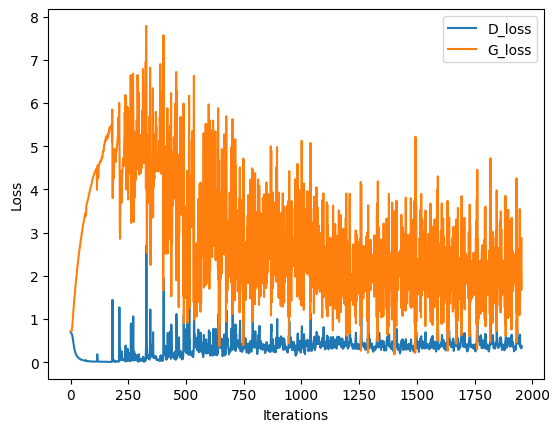

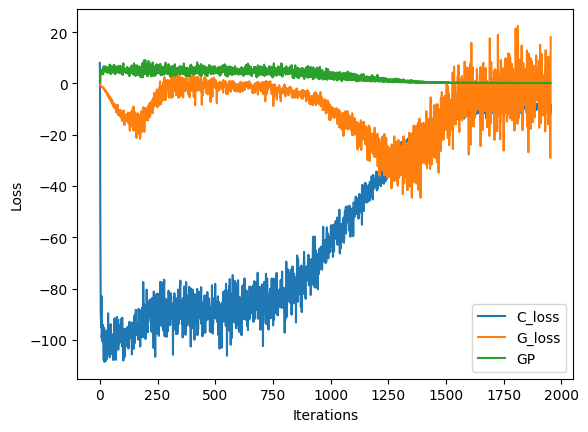

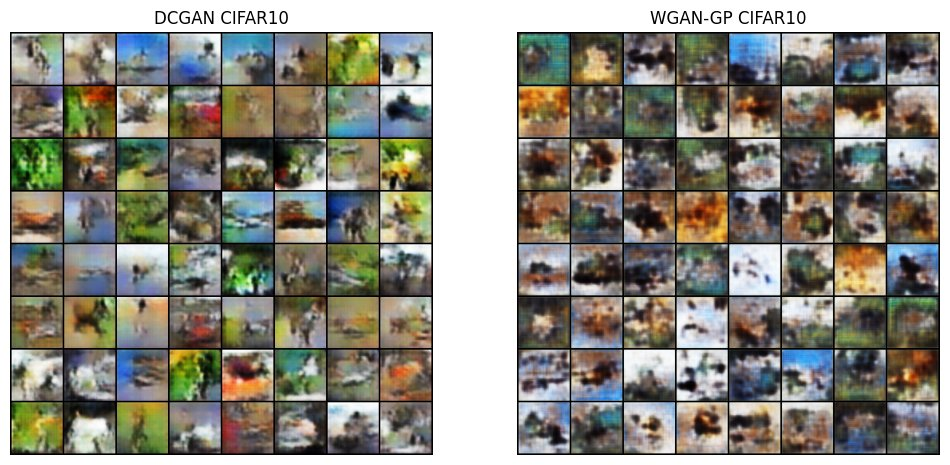

In [19]:
plot_losses(dcgan_cifar_losses)
plot_losses(wgan_cifar_losses)
fixed_noise_cifar = torch.randn(64,Z_DIM,1,1,device=device)
compare_side_by_side(dcgan_cifar_G,wgan_cifar_G,fixed_noise_cifar,title_left="DCGAN CIFAR10",title_right="WGAN-GP CIFAR10",nrow=8)

# <span style="color:#9370DB;"> Analysis (Mode Collapse)</span>

Use **evidence** from:

1) **Side-by-side sample grids** (DCGAN vs WGAN-GP using the same noise)  
2) **Loss curves** (stability / oscillation / divergence)  

Write a short analysis (8–10 lines):

- Where did you observe mode collapse more clearly (Fashion vs CIFAR)?  
- Which model had better diversity and why?  
- How do WGAN-GP changes (critic, Wasserstein loss, gradient penalty, n_critic) help?  
- What do the loss curves suggest about training stability?



from the results, mode collapse seems more noticeable in cifar than in fashion because cifar is a harder dataset with more visual variety and color structure to learn.
in the side-by-side fashion grid, dcgan shows weaker diversity and more repeated-looking shapes, while wgan-gp produces samples that look more varied and consistent.
so overall, wgan-gp had better diversity because it did not get stuck as badly in a small set of outputs.
this mainly comes from replacing the discriminator with a critic and using wazerstein loss, which gives smoother gradients to the generator.
the gradient penalty also helps by enforcing the lipshitz constraint, so training does not become as unstable as standard gan training.
using n_critic helps too, because the critic is trained several times before each generator step, giving the generator a stronger learning signal.
the dcgan loss curves are much more noisy and oscillatory, which suggests less stable adversarial training.
the wgan-gp curves look more controlled and interpretable, and the gradient penalty stays relatively well behaved during trainng.. (the wgan-gp curves look more controlled and interpretable, and the gradient penalty stays relatively well behaved during training)
overall, these results suggest that wgan-gp handles training stability and mode collapse better than dcgan.
so based on both the sample grids and the loss behavior, wgan-gp appears to be the more reliable model here.